In [47]:
import numpy as np
import matplotlib.pyplot as plt

## Question 1a

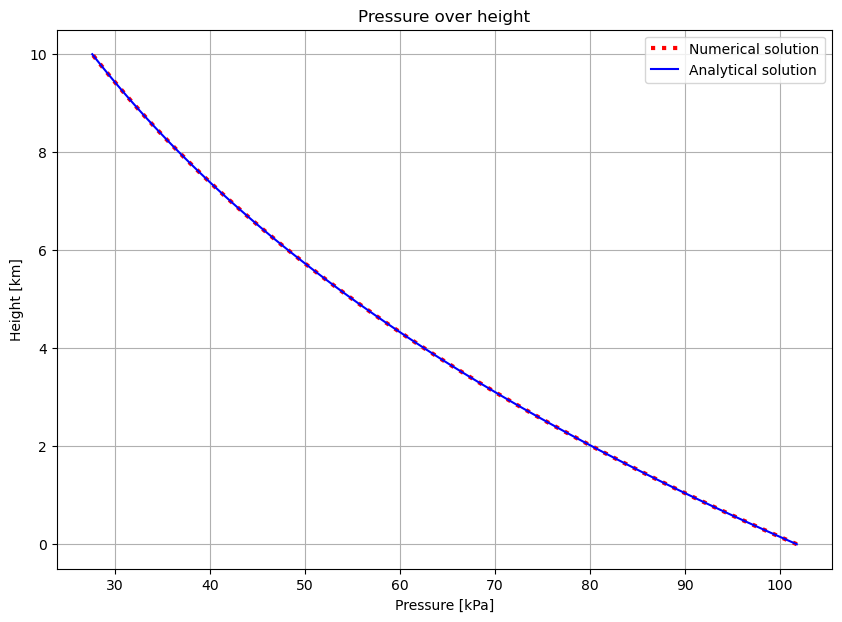

In [48]:
class atmosphere:

    def __init__(self, T_sfc=293, p_sfc=1.018*1e5, gamma=-6/1000):
        self.T_sfc=T_sfc
        self.p_sfc=p_sfc
        self.gamma=gamma

    def p_z(self,z):
        # z must be array

        Rd=287.04
        g=9.81

        self.z=z
        Tz=self.T_sfc+self.gamma*(np.array(z))
        self.Tz = Tz

        #numerical
        p=np.zeros(len(z))
        p[0]=self.p_sfc

        for i in range(len(Tz)-1):
            T=(Tz[i]+Tz[i+1])/2
            p[i+1]=p[i]*np.exp(-g*np.gradient(self.z)[0]/(Rd*T))

        #analytical
        self.pz_analytical=self.p_sfc*((self.T_sfc+self.gamma*self.z)/self.T_sfc)**(-g/(Rd*self.gamma))

        
        self.pz=p
        self.density=p/(Rd*Tz)

    def plot_pz(self):
        #in kPa because it's nice
        plt.plot(self.pz/1000,self.z*1e-3,label='Numerical solution',c='r',linewidth=3,linestyle='dotted')
        plt.plot(self.pz_analytical/1000,self.z*1e-3,label='Analytical solution',c='b')
        

        plt.xlabel("Pressure [kPa]")
        plt.ylabel("Height [km]")
        plt.grid()
        plt.legend()


model = atmosphere()
model.p_z(np.linspace(0,1e4,101))

plt.figure(figsize=(10,7))
plt.title("Pressure over height")
model.plot_pz()

## Question 1b

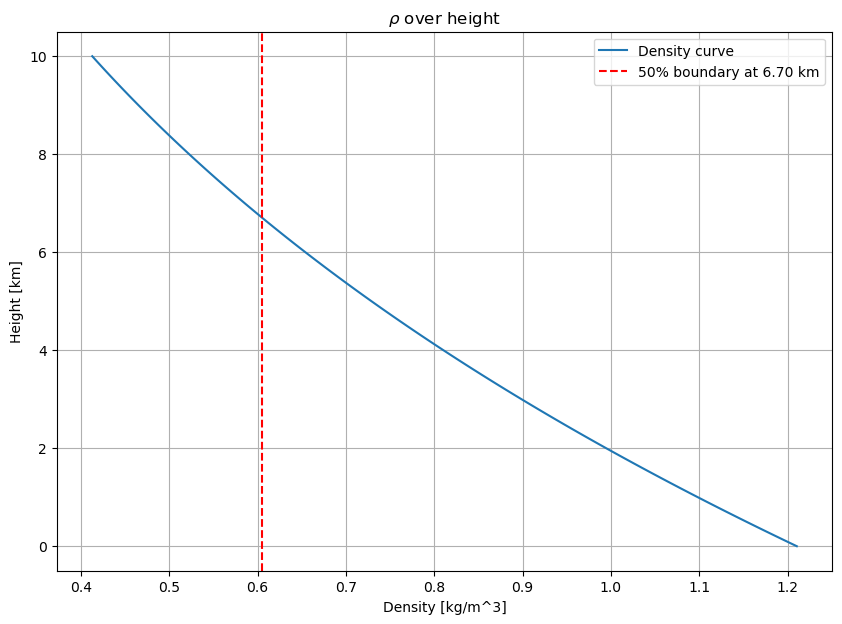

In [49]:
plt.figure(figsize=(10,7))
plt.title(r"$\rho$ over height")

plt.plot(model.density,model.z*1e-3,label="Density curve")

boundary=0.5*model.density[0]
boundary_height=model.z[np.argmin(abs(boundary-model.density))]

plt.axvline(boundary,c='r',linestyle='--',label=f"50% boundary at {boundary_height*1e-3:.2f} km")

plt.xlabel("Density [kg/m^3]")
plt.ylabel("Height [km]")
plt.grid()
plt.legend()

## Question 1c

In [50]:
def e_sat(T_sfc,gamma, z):
    T = T_sfc+gamma*z
    esat = 610.78*np.exp(17.2694 * (T -273.16) / (T - 35.86))
    return esat

def vapor_pressure(RH, z, T_sfc):
    esat = e_sat(T_sfc,model.gamma, z)
    e_v = RH * esat
    return e_v


def q_v(Rd, Rv, p_0, z, T_sfc,  RH):
    e_v = vapor_pressure(RH, z, T_sfc)
    p = model.pz
     
    rv = e_v * Rd / (Rv * p)
    q_vs = rv / (1+ rv)
    return q_vs

At a height of 5 kilometers, the water vapor specific humidity is 3.684E-04 for T: 271 °K
At a height of 5 kilometers, the water vapor specific humidity is 5.430E-03 for T: 303 °K


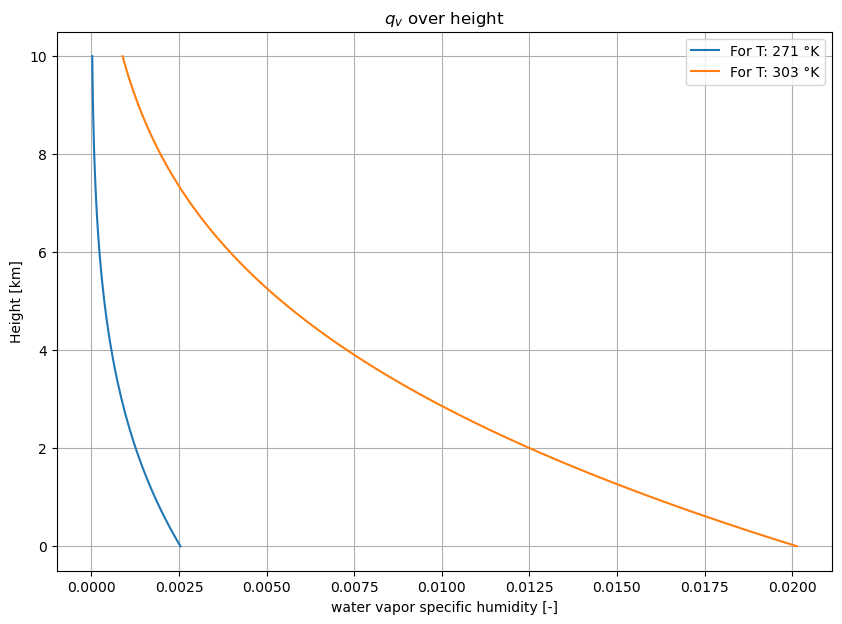

In [51]:
Rv = 461.5
Rd = 287.04
RH = 0.8
T_scf_new = [271, 303]

z = np.linspace(0,1e4,101)
z_int = 5000

plt.figure(figsize=(10,7))
plt.title(r"$q_v$ over height")
for T_surface in T_scf_new:
    q_v_solution = q_v(Rd, Rv, model.p_sfc, z, T_surface,  RH)
    q_5000 = q_v_solution[np.argmin(np.abs(z - z_int))]

    print(f"At a height of 5 kilometers, the water vapor specific humidity is {q_5000:.3E} for T: {T_surface} °K")

    plt.plot(q_v_solution, z*1e-3, label=f'For T: {T_surface} °K')

plt.xlabel("water vapor specific humidity [-]")
plt.ylabel("Height [km]")
plt.grid()
plt.legend()    

## Question 1d

In [52]:
def air_density_z(Rd, T_sfc,gamma, z, p_0):
    T = T = T_sfc+gamma*z
    p = model.pz_analytical

    rho = p / (Rd * T)
    return rho

def WVP(Rd, Rv, T_sfc, gamma, z, p_0, RH):
    rho = air_density_z(Rd, T_sfc, gamma, z, p_0)
    q_vs = q_v(Rd, Rv, p_0, z, T_sfc,  RH)
    
    WVP_value = np.trapezoid(rho * q_vs, z)
    
    return WVP_value

2.8449617401764287 96.29703871046084


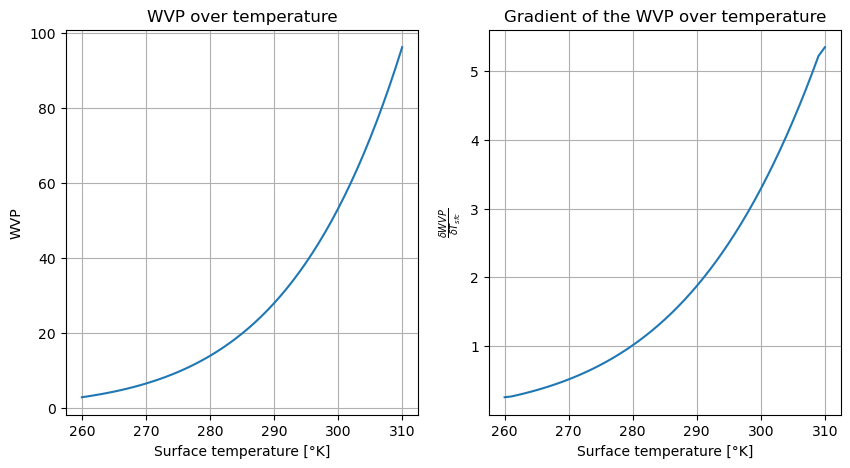

In [53]:
T_range = np.arange(260,310+1,1)

WVP_values = []

for temperature in T_range:
    WVP_values.append(WVP(Rd,Rv, temperature, model.gamma, z, model.p_sfc, RH))
WVP_values = np.array(WVP_values)

min_WVP = np.min(WVP_values)
max_WVP = np.max(WVP_values)
print(min_WVP, max_WVP)

dWVP_dTsfc = np.gradient(WVP_values, T_range)


plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("WVP over temperature")
plt.plot(T_range, WVP_values)

plt.xlabel("Surface temperature [°K]")
plt.ylabel("WVP")
plt.grid() 



plt.subplot(1,2,2)
plt.title("Gradient of the WVP over temperature")
plt.plot(T_range, dWVP_dTsfc)

plt.xlabel("Surface temperature [°K]")
plt.ylabel(r"$\frac{\delta WVP}{\delta T_{sfc}}$")
plt.grid()

## Question 1e

Text(0, 0.5, 'Rainfall rate [mm/h]')

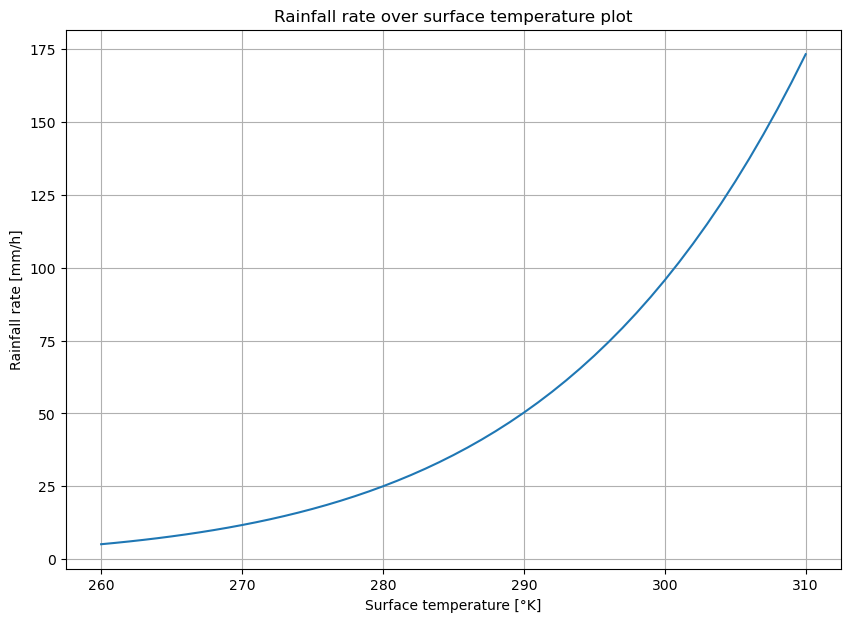

In [54]:
H = 1e4 # height
W = 5 # m/s
velocity = 3600 * W # m / hr

P_mm_per_h = WVP_values * velocity * 1e-4

# 175 mm/h seems a bit intense, even for hot climates
# precipitation at -13 is also interesting
# Other values seem reasonable enough though

plt.figure(figsize=(10,7))
plt.title("Rainfall rate over surface temperature plot")
plt.plot(T_range, P_mm_per_h)

plt.grid()
plt.xlabel("Surface temperature [°K]")
plt.ylabel("Rainfall rate [mm/h]")